# Examen de Big Data – Spark ML
## Parte 2. Clasificación multiclase: deserción y éxito académico

**Autor:** Santiago Caicedo Ortiz · **ID:** U00165112

**Objetivo:** construir con Spark ML un modelo que clasifique a cada estudiante en una de tres clases
(`Dropout`, `Enrolled`, `Graduate`) para que la universidad identifique de forma temprana a quienes están en
riesgo de desertar. El mejor modelo se guarda como `PipelineModel` (`modelo_final`) y lo usa la app de Streamlit.

**Dataset:** *Predict Students' Dropout and Academic Success* (Kaggle), unos 4.400 estudiantes de pregrado con
variables demográficas, socioeconómicas y de rendimiento académico.

El notebook tiene tres secciones:
- **A.** Carga, limpieza, ingeniería de características y partición (tareas 1 a 3).
- **B.** Pipelines, hiperparametrización y validación cruzada (tareas 4 y 5).
- **C.** Evaluación, selección y guardado del mejor modelo (tarea 6).

### Preparación del entorno
Instalamos **PySpark** con una versión fija (4.0.5, la que trae Colab). La app de Streamlit usa la misma versión: así el modelo que
se guarda aquí se puede cargar allá sin problemas de compatibilidad. También instalamos **kagglehub** para
descargar el dataset directamente desde Kaggle, sin subir archivos a mano.

In [ ]:
%pip install -q pyspark==4.0.5 kagglehub

Importamos las librerías y creamos la **SparkSession** con `SparkSession.builder`:
- `spark.driver.memory = 4g`: en Colab la memoria del driver por defecto es limitada.
- `spark.sql.constraintPropagation.enabled = false`: evita que el optimizador "explote" con planes largos
  (muchas columnas derivadas y etapas).
- `spark.sql.shuffle.partitions = 4`: el dataset es pequeño, así que usamos pocas particiones (máximo 4).
  Con las 200 que trae por defecto el entrenamiento sería mucho más lento.

In [1]:
import os, re, json, time, shutil
import pandas as pd
import matplotlib.pyplot as plt

from pyspark.sql import SparkSession, functions as F
from pyspark.sql.types import NumericType
from pyspark.ml import Pipeline, PipelineModel
from pyspark.ml.feature import StringIndexer, OneHotEncoder, VectorAssembler, StandardScaler
from pyspark.ml.classification import LogisticRegression, RandomForestClassifier, DecisionTreeClassifier
from pyspark.ml.tuning import ParamGridBuilder, CrossValidator
from pyspark.ml.evaluation import MulticlassClassificationEvaluator

SEED = 42
N_PARTICIONES = 4

spark = (SparkSession.builder
         .appName("dropout_sparkml")
         .config("spark.driver.memory", "4g")
         .config("spark.sql.constraintPropagation.enabled", "false")  # evita la explosión del optimizador
         .config("spark.sql.shuffle.partitions", str(N_PARTICIONES))
         .getOrCreate())
spark.sparkContext.setLogLevel("ERROR")
print("Spark", spark.version)

Spark 4.0.5


---
# A. Carga, limpieza, ingeniería de características y partición

## 1. Carga y exploración
Descargamos la última versión del dataset con `kagglehub`. Devuelve la carpeta local donde quedó el CSV.

In [2]:
import kagglehub

path = kagglehub.dataset_download("thedevastator/higher-education-predictors-of-student-retention")
print("Archivos descargados:", os.listdir(path))
csv_path = os.path.join(path, "dataset.csv")

Using Colab cache for faster access to the 'higher-education-predictors-of-student-retention' dataset.
Archivos descargados: ['dataset.csv']


**Separador.** El enunciado indica que el CSV usa punto y coma (`;`). Sin embargo, la versión de este enlace de
Kaggle viene separada por comas (`,`). Para no depender de la versión, leemos la primera línea y elegimos el
separador que más aparece. Luego cargamos con Spark indicando **encabezado** (`header=True`), **detección
automática de tipos** (`inferSchema=True`) y el **separador correcto**.

In [3]:
with open(csv_path, encoding="utf-8") as f:
    encabezado = f.readline()
SEP = ";" if encabezado.count(";") > encabezado.count(",") else ","
print(f"Separador detectado: '{SEP}'")

df_raw = spark.read.csv(csv_path, header=True, inferSchema=True, sep=SEP)
df_raw.printSchema()

Separador detectado: ','
root
 |-- Marital status: integer (nullable = true)
 |-- Application mode: integer (nullable = true)
 |-- Application order: integer (nullable = true)
 |-- Course: integer (nullable = true)
 |-- Daytime/evening attendance: integer (nullable = true)
 |-- Previous qualification: integer (nullable = true)
 |-- Nacionality: integer (nullable = true)
 |-- Mother's qualification: integer (nullable = true)
 |-- Father's qualification: integer (nullable = true)
 |-- Mother's occupation: integer (nullable = true)
 |-- Father's occupation: integer (nullable = true)
 |-- Displaced: integer (nullable = true)
 |-- Educational special needs: integer (nullable = true)
 |-- Debtor: integer (nullable = true)
 |-- Tuition fees up to date: integer (nullable = true)
 |-- Gender: integer (nullable = true)
 |-- Scholarship holder: integer (nullable = true)
 |-- Age at enrollment: integer (nullable = true)
 |-- International: integer (nullable = true)
 |-- Curricular units 1st sem (c

Número de filas y de columnas, y **distribución de las clases** (conteo y porcentaje por `Target`).

Filas: 4424  |  Columnas: 35
+--------+-----+----------+
|  Target|count|porcentaje|
+--------+-----+----------+
|Graduate| 2209|     49.93|
| Dropout| 1421|     32.12|
|Enrolled|  794|     17.95|
+--------+-----+----------+



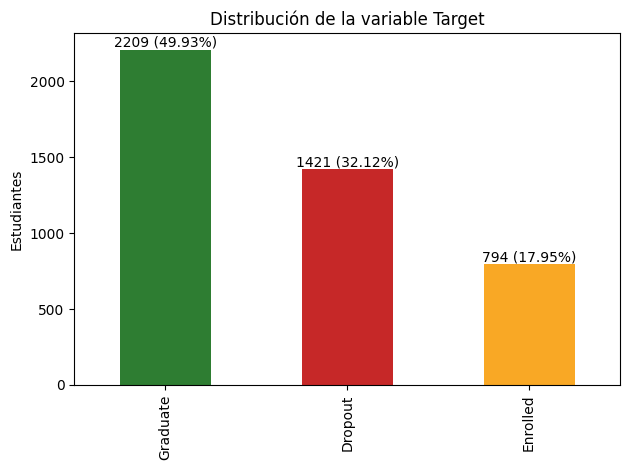

In [4]:
n_filas, n_cols = df_raw.count(), len(df_raw.columns)
print(f"Filas: {n_filas}  |  Columnas: {n_cols}")

dist = (df_raw.groupBy("Target").count()
        .withColumn("porcentaje", F.round(F.col("count") / n_filas * 100, 2))
        .orderBy(F.desc("count")))
dist.show()

pdf_dist = dist.toPandas()
colores = {"Graduate": "#2e7d32", "Dropout": "#c62828", "Enrolled": "#f9a825"}
ax = pdf_dist.plot.bar(x="Target", y="count", legend=False,
                       color=[colores.get(t, "gray") for t in pdf_dist["Target"]])
ax.set_title("Distribución de la variable Target")
ax.set_ylabel("Estudiantes"); ax.set_xlabel("")
for i, (c, p) in enumerate(zip(pdf_dist["count"], pdf_dist["porcentaje"])):
    ax.text(i, c + 20, f"{c} ({p}%)", ha="center")
plt.tight_layout(); plt.show()

### Análisis del desbalance
- **Clase dominante: `Graduate`**, con unos 2.209 estudiantes (≈ 50 %).
- **Clase minoritaria: `Enrolled`**, con unos 794 estudiantes (≈ 18 %). `Dropout` queda en el medio, con unos
  1.421 (≈ 32 %).
- La proporción entre la clase mayoritaria y la minoritaria es de casi **2,8 a 1**.

**Por qué importa:**
1. Un modelo que prediga siempre `Graduate` tendría ≈ 50 % de *accuracy* sin aprender nada. Por eso la
   *accuracy* sola es engañosa.
2. Los algoritmos minimizan el error global. Si no se corrige, tienden a favorecer la clase mayoritaria y a
   sacrificar la minoritaria.
3. Para el negocio, la clase más importante es **`Dropout`**: la universidad quiere detectar a tiempo a quienes
   van a desertar. `Enrolled` es la más difícil porque es un estado intermedio (estudiantes que siguen
   matriculados pero aún no se gradúan). Un error en estas clases cuesta más que confundir a un graduado.

## 2. Preprocesamiento
### 2.1 Normalización de nombres de columnas
Pasamos los nombres a minúsculas y, con una **expresión regular**, reemplazamos todo lo que no sea letra o
número (espacios, paréntesis, `/`, `'`) por `_`. Así quedan nombres válidos y fáciles de usar en el código y en
la app, por ejemplo `Curricular units 1st sem (approved)` → `curricular_units_1st_sem_approved`.

In [5]:
def normalizar(nombre):
    nombre = nombre.strip().lower()
    nombre = re.sub(r"[^a-z0-9]+", "_", nombre)   # cualquier secuencia de símbolos/espacios -> "_"
    return nombre.strip("_")

df = df_raw.toDF(*[normalizar(c) for c in df_raw.columns])
for antes, despues in list(zip(df_raw.columns, df.columns))[:8]:
    print(f"{antes!r:45} -> {despues}")
print("...")
print(df.columns)

'Marital status'                              -> marital_status
'Application mode'                            -> application_mode
'Application order'                           -> application_order
'Course'                                      -> course
'Daytime/evening attendance'                  -> daytime_evening_attendance
'Previous qualification'                      -> previous_qualification
'Nacionality'                                 -> nacionality
"Mother's qualification"                      -> mother_s_qualification
...
['marital_status', 'application_mode', 'application_order', 'course', 'daytime_evening_attendance', 'previous_qualification', 'nacionality', 'mother_s_qualification', 'father_s_qualification', 'mother_s_occupation', 'father_s_occupation', 'displaced', 'educational_special_needs', 'debtor', 'tuition_fees_up_to_date', 'gender', 'scholarship_holder', 'age_at_enrollment', 'international', 'curricular_units_1st_sem_credited', 'curricular_units_1st_sem_enrolled', 

### 2.2 Duplicados, nulos y tipos de dato
Eliminamos las filas duplicadas (una fila repetida aparecería en train y test e inflaría las métricas). Luego
contamos los nulos por columna y eliminamos las filas incompletas, si las hay.

In [6]:
antes = df.count()
df = df.dropDuplicates()
print(f"Duplicados eliminados: {antes - df.count()}")

nulos = df.select([F.sum(F.col(c).isNull().cast("int")).alias(c) for c in df.columns]).toPandas().T
nulos.columns = ["nulos"]
print("Total de valores nulos:", int(nulos["nulos"].sum()))
if nulos["nulos"].sum() > 0:
    print(nulos[nulos["nulos"] > 0])
df = df.dropna()
print("Filas después de la limpieza:", df.count())

Duplicados eliminados: 0
Total de valores nulos: 0
Filas después de la limpieza: 4424


Verificamos los tipos: todas las variables explicativas deben ser numéricas (enteros o decimales). La única
columna de texto debe ser `target`.

In [7]:
tipos = pd.Series({f.name: f.dataType.simpleString() for f in df.schema.fields})
print(tipos.value_counts())
no_numericas = [f.name for f in df.schema.fields if not isinstance(f.dataType, NumericType)]
print("Columnas no numéricas:", no_numericas)
assert no_numericas == ["target"], "Hay columnas con tipo inesperado"
df = df.withColumn("target", F.trim(F.col("target")))

int       29
double     5
string     1
Name: count, dtype: int64
Columnas no numéricas: ['target']


### 2.3 Estrategia para el desbalance de clases
Combinamos dos medidas:

1. **Pesos por clase (`weightCol`).** Cada fila recibe un peso inversamente proporcional a la frecuencia de su
   clase: $w_c = \dfrac{N}{K \cdot n_c}$ ($N$ filas de entrenamiento, $K = 3$ clases, $n_c$ filas de la clase
   $c$). Así un error en `Enrolled` "pesa" más que uno en `Graduate`. Los tres algoritmos
   (LogisticRegression, RandomForest y DecisionTree) aceptan `weightCol`. Los pesos se calculan **solo con el
   conjunto de entrenamiento** para no filtrar información del de prueba.
2. **F1 ponderado como métrica de selección** en `CrossValidator`. Combina precisión y recall de cada clase y no
   se deja engañar por la clase mayoritaria como la *accuracy*.

**Por qué no remuestreo:** el *oversampling* duplica filas de las clases pequeñas, lo que favorece el
sobreajuste y, dentro de la validación cruzada, puede poner copias de la misma fila en folds distintos. El
*undersampling* descartaría más de la mitad de los `Graduate` en un dataset que ya es pequeño (unas 4.400
filas). Los pesos corrigen el desbalance sin perder ni duplicar información.

### 2.4 Indexado de la etiqueta (fuera del pipeline)
Convertimos `target` en `label` numérico con `StringIndexer`, **fuera del pipeline**. Así el `PipelineModel`
guardado no necesita la columna `target` para predecir (en la app no existe). Guardamos el orden de las clases
(`LABELS`): la app lo usa para traducir el índice predicho y las probabilidades a nombres de clase.

In [8]:
label_indexer = StringIndexer(inputCol="target", outputCol="label", stringOrderType="frequencyDesc").fit(df)
LABELS = list(label_indexer.labels)
print("Orden de las clases (índice -> clase):", dict(enumerate(LABELS)))

df = label_indexer.transform(df)
# Reparticionamos de forma determinista (hash de todas las columnas) a 4 particiones y guardamos en caché,
# para que randomSplit produzca siempre la misma partición.
df = df.repartition(N_PARTICIONES, *df.columns).cache()
df.count()

Orden de las clases (índice -> clase): {0: 'Graduate', 1: 'Dropout', 2: 'Enrolled'}


4424

### 2.5 Partición entrenamiento / prueba
Dividimos 80/20 con `randomSplit` y semilla fija 42 (reproducible). Después calculamos los pesos por clase
solo con `train` y los agregamos como columna `class_weight`.

In [9]:
train, test = df.randomSplit([0.8, 0.2], seed=SEED)

n_train, K = train.count(), len(LABELS)
conteos = {r["label"]: r["count"] for r in train.groupBy("label").count().collect()}
PESOS = {lbl: n_train / (K * c) for lbl, c in conteos.items()}
print("Pesos por clase:", {LABELS[int(l)]: round(w, 3) for l, w in sorted(PESOS.items())})

mapa_pesos = F.create_map(*[x for l, w in PESOS.items() for x in (F.lit(l), F.lit(w))])
train = train.withColumn("class_weight", mapa_pesos[F.col("label")])
test = test.withColumn("class_weight", mapa_pesos[F.col("label")])

print(f"Train: {n_train} filas  |  Test: {test.count()} filas")
train.groupBy("target").count().orderBy(F.desc("count")).show()

Pesos por clase: {'Graduate': 0.671, 'Dropout': 1.009, 'Enrolled': 1.93}
Train: 3579 filas  |  Test: 845 filas
+--------+-----+
|  target|count|
+--------+-----+
|Graduate| 1779|
| Dropout| 1182|
|Enrolled|  618|
+--------+-----+



## 3. Ingeniería de características
### 3.1 Variables derivadas
Creamos 4 variables con sentido académico. En las divisiones, si el denominador es 0 (el estudiante no inscribió
o no presentó materias) el resultado es 0, para evitar nulos o infinitos.

| Variable | Fórmula | Qué mide |
|---|---|---|
| `tasa_aprobacion_1s` | aprobadas 1.er sem / inscritas 1.er sem | Qué proporción de lo que inscribió aprobó en el primer semestre. |
| `tasa_aprobacion_2s` | aprobadas 2.º sem / inscritas 2.º sem | Lo mismo en el segundo semestre; una tasa baja es señal fuerte de deserción. |
| `variacion_nota` | nota 2.º sem − nota 1.er sem | Tendencia del rendimiento: positiva si mejora, negativa si empeora. |
| `eficiencia_evaluacion_2s` | aprobadas 2.º sem / evaluaciones 2.º sem | Cuántas de las materias que presentó a evaluación terminó aprobando. |

La misma función se replica en la app de Streamlit, que calcula estas variables a partir del formulario.

In [10]:
def tasa(num, den):
    return F.when(F.col(den) > 0, F.col(num) / F.col(den)).otherwise(F.lit(0.0))

def agregar_variables_derivadas(d):
    return (d
        .withColumn("tasa_aprobacion_1s", tasa("curricular_units_1st_sem_approved", "curricular_units_1st_sem_enrolled"))
        .withColumn("tasa_aprobacion_2s", tasa("curricular_units_2nd_sem_approved", "curricular_units_2nd_sem_enrolled"))
        .withColumn("variacion_nota", F.col("curricular_units_2nd_sem_grade") - F.col("curricular_units_1st_sem_grade"))
        .withColumn("eficiencia_evaluacion_2s", tasa("curricular_units_2nd_sem_approved", "curricular_units_2nd_sem_evaluations")))

DERIVADAS = ["tasa_aprobacion_1s", "tasa_aprobacion_2s", "variacion_nota", "eficiencia_evaluacion_2s"]
train = agregar_variables_derivadas(train).cache()
test = agregar_variables_derivadas(test).cache()
train.count(), test.count()

train.groupBy("target").agg(*[F.round(F.avg(c), 3).alias(c) for c in DERIVADAS]).show()

+--------+------------------+------------------+--------------+------------------------+
|  target|tasa_aprobacion_1s|tasa_aprobacion_2s|variacion_nota|eficiencia_evaluacion_2s|
+--------+------------------+------------------+--------------+------------------------+
|Graduate|             0.905|             0.901|         0.066|                    0.77|
|Enrolled|             0.678|              0.64|         0.042|                   0.439|
| Dropout|             0.383|             0.291|        -1.371|                    0.21|
+--------+------------------+------------------+--------------+------------------------+



Los promedios por clase confirman que las variables derivadas separan bien las clases. Los `Dropout` tienen tasas
de aprobación mucho más bajas que los `Graduate`, y los `Enrolled` quedan en el medio.

### 3.2 Variables categóricas y numéricas
Aunque todas las columnas vienen como números, varias son **códigos de categorías nominales**: el número no
indica orden ni magnitud (el curso 9.254 no es "mayor" que el 171). Si se dejan como números, el modelo lineal
interpretaría un orden falso. Por eso las codificamos con `StringIndexer` y `OneHotEncoder`:

`marital_status`, `application_mode`, `course`, `previous_qualification`, `nacionality`, `mother_s_qualification`,
`father_s_qualification`, `mother_s_occupation`, `father_s_occupation`.

Las variables binarias (0/1, por ejemplo `debtor` o `scholarship_holder`) ya están bien codificadas y se tratan
como numéricas, igual que las cantidades, las notas, la edad, los indicadores macroeconómicos y las derivadas.

In [11]:
CATEGORICAS = ["marital_status", "application_mode", "course", "previous_qualification", "nacionality",
               "mother_s_qualification", "father_s_qualification", "mother_s_occupation", "father_s_occupation"]
NO_FEATURES = {"target", "label", "class_weight"}
NUMERICAS = [c for c in train.columns if c not in CATEGORICAS and c not in NO_FEATURES]

print(f"{len(CATEGORICAS)} categóricas: {CATEGORICAS}")
print(f"{len(NUMERICAS)} numéricas: {NUMERICAS}")

9 categóricas: ['marital_status', 'application_mode', 'course', 'previous_qualification', 'nacionality', 'mother_s_qualification', 'father_s_qualification', 'mother_s_occupation', 'father_s_occupation']
29 numéricas: ['application_order', 'daytime_evening_attendance', 'displaced', 'educational_special_needs', 'debtor', 'tuition_fees_up_to_date', 'gender', 'scholarship_holder', 'age_at_enrollment', 'international', 'curricular_units_1st_sem_credited', 'curricular_units_1st_sem_enrolled', 'curricular_units_1st_sem_evaluations', 'curricular_units_1st_sem_approved', 'curricular_units_1st_sem_grade', 'curricular_units_1st_sem_without_evaluations', 'curricular_units_2nd_sem_credited', 'curricular_units_2nd_sem_enrolled', 'curricular_units_2nd_sem_evaluations', 'curricular_units_2nd_sem_approved', 'curricular_units_2nd_sem_grade', 'curricular_units_2nd_sem_without_evaluations', 'unemployment_rate', 'inflation_rate', 'gdp', 'tasa_aprobacion_1s', 'tasa_aprobacion_2s', 'variacion_nota', 'eficien

### 3.3 Etapas de preprocesamiento (dentro del Pipeline)
Definimos las etapas comunes que van **dentro** de cada pipeline:
1. `StringIndexer(handleInvalid="keep")`: convierte cada código categórico en un índice. `keep` reserva un
   índice extra para categorías que no se vieron en el entrenamiento (por ejemplo, un código nuevo que llegue
   desde la app), en lugar de fallar.
2. `OneHotEncoder`: convierte cada índice en un vector binario.
3. `VectorAssembler`: une las categóricas codificadas y las numéricas en un solo vector.
4. `StandardScaler`: escala cada característica a desviación estándar 1. Es clave para la regresión logística
   con regularización, porque sin escalar las variables con valores grandes (por ejemplo, la edad) dominarían a
   las pequeñas (las tasas entre 0 y 1). A los árboles no les afecta.

Como todo va dentro del pipeline, la validación cruzada ajusta el indexado y el escalado **solo con los datos de
cada fold de entrenamiento** (sin fuga de información). El modelo guardado aplica exactamente la misma
transformación en la app.

In [12]:
def etapas_preprocesamiento(categoricas, numericas):
    idx = [f"{c}_idx" for c in categoricas]
    ohe = [f"{c}_ohe" for c in categoricas]
    return [
        StringIndexer(inputCols=categoricas, outputCols=idx, handleInvalid="keep"),
        OneHotEncoder(inputCols=idx, outputCols=ohe, handleInvalid="keep"),
        VectorAssembler(inputCols=ohe + numericas, outputCol="features_raw", handleInvalid="keep"),
        StandardScaler(inputCol="features_raw", outputCol="features", withMean=False, withStd=True),
    ]

### 3.4 Selección de variables con `featureImportances`
Entrenamos un Random Forest exploratorio (solo con `train`) y sumamos la importancia de cada vector one-hot para
obtener la importancia de cada **variable original**. Las variables con importancia menor a 0,5 % aportan muy
poco a la predicción: las descartamos para simplificar el modelo y el formulario de la app.

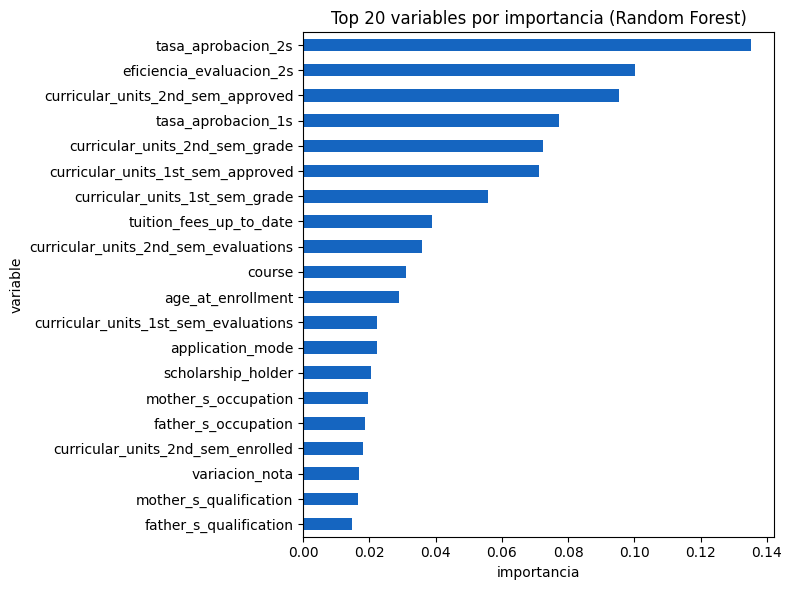

Variables descartadas (importancia < 0.5%):
variable
application_order                               0.0042
curricular_units_1st_sem_credited               0.0039
curricular_units_2nd_sem_credited               0.0039
curricular_units_2nd_sem_without_evaluations    0.0029
curricular_units_1st_sem_without_evaluations    0.0026
displaced                                       0.0024
nacionality                                     0.0021
daytime_evening_attendance                      0.0015
international                                   0.0006
educational_special_needs                       0.0003

Variables finales: 8 categóricas + 20 numéricas


In [13]:
etapas = etapas_preprocesamiento(CATEGORICAS, NUMERICAS)
rf_exploratorio = RandomForestClassifier(featuresCol="features_raw", labelCol="label", weightCol="class_weight",
                                         numTrees=100, maxDepth=8, seed=SEED)
modelo_sel = Pipeline(stages=etapas[:3] + [rf_exploratorio]).fit(train)

# nombre de cada posición del vector de características (metadatos del VectorAssembler)
meta = modelo_sel.transform(train.limit(1)).schema["features_raw"].metadata["ml_attr"]["attrs"]
nombres = {a["idx"]: a["name"] for grupo in meta.values() for a in grupo}

def variable_original(nombre_attr):
    for c in CATEGORICAS:
        if nombre_attr.startswith(f"{c}_ohe"):
            return c
    return nombre_attr

imp = modelo_sel.stages[-1].featureImportances.toArray()
importancias = (pd.DataFrame({"variable": [variable_original(nombres[i]) for i in range(len(imp))], "importancia": imp})
                .groupby("variable")["importancia"].sum().sort_values(ascending=False))

ax = importancias.head(20)[::-1].plot.barh(figsize=(8, 6), color="#1565c0")
ax.set_title("Top 20 variables por importancia (Random Forest)"); ax.set_xlabel("importancia")
plt.tight_layout(); plt.show()

UMBRAL = 0.005
descartadas = importancias[importancias < UMBRAL].index.tolist()
print(f"Variables descartadas (importancia < {UMBRAL:.1%}):")
print(importancias[importancias < UMBRAL].round(4).to_string())

CAT_FINAL = [c for c in CATEGORICAS if c not in descartadas]
NUM_FINAL = [c for c in NUMERICAS if c not in descartadas]
print(f"\nVariables finales: {len(CAT_FINAL)} categóricas + {len(NUM_FINAL)} numéricas")

**Análisis de la selección de variables.**

- Las variables más importantes son las de **rendimiento académico**, y encabezan **dos de nuestras variables derivadas**: `tasa_aprobacion_2s` (≈ 13,5 %) y `eficiencia_evaluacion_2s` (≈ 10 %). Les siguen las materias aprobadas del 2.º semestre, `tasa_aprobacion_1s` y las notas de ambos semestres. La ingeniería de características aportó información útil: las proporciones resumen mejor el desempeño que los conteos absolutos.
- Después aparecen factores **económicos y de contexto**: `tuition_fees_up_to_date` (matrícula al día), `course`, `age_at_enrollment`, `application_mode` y `scholarship_holder`.
- Se descartan **10 variables** con importancia menor a 0,5 %: `application_order`, materias homologadas (`credited`) y sin evaluación (`without_evaluations`) de ambos semestres, `displaced`, `nacionality`, `daytime_evening_attendance`, `international` y `educational_special_needs`. Casi todas son binarias muy desbalanceadas (por ejemplo, muy pocos estudiantes internacionales o con necesidades especiales) o columnas que casi siempre valen 0, así que el modelo casi no las usa para separar las clases.
- Resultado: **8 categóricas + 20 numéricas** (incluidas las 4 derivadas). El modelo queda más simple y el formulario de la app más corto, sin perder capacidad predictiva.

---
# B. Pipelines, hiperparametrización y validación cruzada

## 4. Modelos con Pipeline
Cada modelo es un **Pipeline completo**: indexado → codificación one-hot → ensamblado → escalado → clasificador.
Los tres usan `weightCol="class_weight"` para el desbalance y semilla fija cuando el algoritmo es aleatorio:
- **LogisticRegression (`family="multinomial"`)**: modelo lineal que estima directamente una probabilidad por
  cada una de las 3 clases (softmax). Es un buen punto de referencia y es fácil de interpretar.
- **RandomForestClassifier**: conjunto de árboles entrenados sobre muestras aleatorias. Capta relaciones no
  lineales e interacciones y suele ser robusto al sobreajuste.
- **DecisionTreeClassifier**: un solo árbol. Es muy interpretable, pero tiende a sobreajustar.

In [14]:
def crear_pipeline(clasificador):
    return Pipeline(stages=etapas_preprocesamiento(CAT_FINAL, NUM_FINAL) + [clasificador])

lr = LogisticRegression(family="multinomial", featuresCol="features", labelCol="label",
                        weightCol="class_weight", maxIter=100)
rf = RandomForestClassifier(featuresCol="features", labelCol="label", weightCol="class_weight", seed=SEED)
dt = DecisionTreeClassifier(featuresCol="features", labelCol="label", weightCol="class_weight", seed=SEED)

pipelines = {
    "LogisticRegression": crear_pipeline(lr),
    "RandomForest": crear_pipeline(rf),
    "DecisionTree": crear_pipeline(dt),
}
for nombre, p in pipelines.items():
    print(nombre, "->", [type(s).__name__ for s in p.getStages()])

LogisticRegression -> ['StringIndexer', 'OneHotEncoder', 'VectorAssembler', 'StandardScaler', 'LogisticRegression']
RandomForest -> ['StringIndexer', 'OneHotEncoder', 'VectorAssembler', 'StandardScaler', 'RandomForestClassifier']
DecisionTree -> ['StringIndexer', 'OneHotEncoder', 'VectorAssembler', 'StandardScaler', 'DecisionTreeClassifier']


## 5. Hiperparametrización con validación cruzada
Para cada modelo armamos una rejilla con `ParamGridBuilder().build()` de **2 hiperparámetros × 2 valores**
(4 combinaciones). `CrossValidator` con `numFolds=3` entrena cada combinación 3 veces (12 entrenamientos por
modelo) y elige la de mayor **F1 ponderado** promedio:
- **LogisticRegression**: `regParam` (fuerza de la regularización) y `elasticNetParam` (0 = L2/Ridge,
  0,5 = mezcla de L1 y L2).
- **RandomForest**: `numTrees` (cantidad de árboles) y `maxDepth` (profundidad de cada árbol).
- **DecisionTree**: `maxDepth` y `minInstancesPerNode` (mínimo de filas por hoja; valores altos podan el árbol).

In [15]:
evaluador_f1 = MulticlassClassificationEvaluator(labelCol="label", predictionCol="prediction", metricName="f1")

rejillas = {
    "LogisticRegression": (ParamGridBuilder()
                           .addGrid(lr.regParam, [0.01, 0.1])
                           .addGrid(lr.elasticNetParam, [0.0, 0.5])
                           .build()),
    "RandomForest": (ParamGridBuilder()
                     .addGrid(rf.numTrees, [50, 100])
                     .addGrid(rf.maxDepth, [5, 10])
                     .build()),
    "DecisionTree": (ParamGridBuilder()
                     .addGrid(dt.maxDepth, [5, 10])
                     .addGrid(dt.minInstancesPerNode, [1, 10])
                     .build()),
}

modelos_cv = {}
for nombre, pipe in pipelines.items():
    t0 = time.time()
    cv = CrossValidator(estimator=pipe, estimatorParamMaps=rejillas[nombre], evaluator=evaluador_f1,
                        numFolds=3, seed=SEED, parallelism=2)
    modelos_cv[nombre] = cv.fit(train)
    print(f"{nombre:20} F1 CV máximo = {max(modelos_cv[nombre].avgMetrics):.4f}   ({time.time() - t0:.0f} s)")

LogisticRegression   F1 CV máximo = 0.7591   (137 s)
RandomForest         F1 CV máximo = 0.7645   (112 s)
DecisionTree         F1 CV máximo = 0.7322   (50 s)


F1 promedio de validación cruzada de **cada combinación** y los **mejores hiperparámetros** de cada modelo:

In [16]:
filas = []
for nombre, cvm in modelos_cv.items():
    for params, f1 in zip(cvm.getEstimatorParamMaps(), cvm.avgMetrics):
        filas.append({"modelo": nombre, **{p.name: v for p, v in params.items()}, "f1_cv": round(f1, 4)})
tabla_cv = pd.DataFrame(filas)
display(tabla_cv)

mejores_params = {}
for nombre, cvm in modelos_cv.items():
    clf = cvm.bestModel.stages[-1]
    nombres_param = [p.name for p in rejillas[nombre][0].keys()]
    mejores_params[nombre] = {n: clf.getOrDefault(clf.getParam(n)) for n in nombres_param}
    print(f"{nombre:20} mejores hiperparámetros: {mejores_params[nombre]}")

,modelo,regParam,elasticNetParam,f1_cv,numTrees,maxDepth,minInstancesPerNode
0,LogisticRegression,0.01,0.0,0.7512,NaN,NaN,NaN
1,LogisticRegression,0.01,0.5,0.7591,NaN,NaN,NaN
2,LogisticRegression,0.10,0.0,0.7521,NaN,NaN,NaN
3,LogisticRegression,0.10,0.5,0.7422,NaN,NaN,NaN
4,RandomForest,NaN,NaN,0.7472,50.0,5.0,NaN
5,RandomForest,NaN,NaN,0.7617,50.0,10.0,NaN
6,RandomForest,NaN,NaN,0.7460,100.0,5.0,NaN
7,RandomForest,NaN,NaN,0.7645,100.0,10.0,NaN
8,DecisionTree,NaN,NaN,0.7322,NaN,5.0,1.0
9,DecisionTree,NaN,NaN,0.7320,NaN,5.0,10.0


LogisticRegression   mejores hiperparámetros: {'regParam': 0.01, 'elasticNetParam': 0.5}
RandomForest         mejores hiperparámetros: {'numTrees': 100, 'maxDepth': 10}
DecisionTree         mejores hiperparámetros: {'maxDepth': 5, 'minInstancesPerNode': 1}


**Análisis de los mejores hiperparámetros (F1 de validación cruzada):**

| Modelo | Mejores hiperparámetros | F1 CV |
|---|---|---|
| RandomForest | `numTrees=100`, `maxDepth=10` | **0,7645** |
| LogisticRegression | `regParam=0.01`, `elasticNetParam=0.5` | 0,7591 |
| DecisionTree | `maxDepth=5`, `minInstancesPerNode=1` | 0,7322 |

- **LogisticRegression:** gana la regularización **suave** (`regParam=0.01`). Con `0.1` y mezcla L1/L2 el F1 baja a 0,742, porque una penalización fuerte simplifica demasiado el modelo (subajuste). Con `regParam=0.01`, la mezcla `elasticNetParam=0.5` supera a la L2 pura (0,7591 frente a 0,7512): la parte L1 lleva a cero los coeficientes de las categorías one-hot poco útiles y funciona como una selección de variables adicional.
- **RandomForest:** el hiperparámetro decisivo es `maxDepth`. Pasar de 5 a 10 sube el F1 de ≈ 0,747 a ≈ 0,763, porque árboles más profundos capturan interacciones (por ejemplo, tasa de aprobación baja *y* matrícula atrasada). Pasar de 50 a 100 árboles mejora muy poco (0,7617 → 0,7645): más árboles solo reducen la varianza y el bosque ya es estable con 50.
- **DecisionTree:** el mejor es el árbol **poco profundo** (`maxDepth=5`). Con profundidad 10 el F1 cae a ≈ 0,71-0,72, porque un solo árbol profundo **sobreajusta** el entrenamiento. Por eso el bosque, que promedia muchos árboles, sí aprovecha la profundidad. Con `maxDepth=5`, `minInstancesPerNode` casi no cambia nada (0,7322 frente a 0,7320), porque el límite de profundidad ya poda el árbol.
- En validación cruzada el RandomForest queda ligeramente por encima de la regresión logística, pero la diferencia (≈ 0,005) es muy pequeña. La decisión final se toma sobre el conjunto de prueba (sección C).

---
# C. Evaluación, selección y guardado del mejor modelo

## 6. Evaluación sobre el conjunto de prueba
Evaluamos el mejor modelo de cada validación cruzada (`bestModel`) **solo sobre `test`**, datos que ningún
modelo vio durante el entrenamiento ni la selección de hiperparámetros. Calculamos *accuracy*, F1 ponderado,
precisión ponderada y recall ponderado. También el F1 de cada clase, para ver cómo le va a cada modelo con
`Dropout` y con la minoritaria `Enrolled`.

In [17]:
def evaluar(pred, metrica, etiqueta=None):
    ev = MulticlassClassificationEvaluator(labelCol="label", predictionCol="prediction", metricName=metrica)
    if etiqueta is not None:
        ev.setMetricLabel(float(etiqueta))
    return ev.evaluate(pred)

predicciones, filas = {}, []
for nombre, cvm in modelos_cv.items():
    pred = cvm.bestModel.transform(test).cache()
    predicciones[nombre] = pred
    fila = {"modelo": nombre,
            "accuracy": evaluar(pred, "accuracy"),
            "f1_ponderado": evaluar(pred, "f1"),
            "precision_ponderada": evaluar(pred, "weightedPrecision"),
            "recall_ponderado": evaluar(pred, "weightedRecall")}
    for i, clase in enumerate(LABELS):
        fila[f"f1_{clase}"] = evaluar(pred, "fMeasureByLabel", i)
    filas.append(fila)

comparacion = pd.DataFrame(filas).sort_values("f1_ponderado", ascending=False).reset_index(drop=True).round(4)
display(comparacion)

,modelo,accuracy,f1_ponderado,precision_ponderada,recall_ponderado,f1_Graduate,f1_Dropout,f1_Enrolled
0,LogisticRegression,0.7396,0.7466,0.7585,0.7396,0.8231,0.7785,0.5165
1,RandomForest,0.7302,0.7333,0.7397,0.7302,0.8170,0.7506,0.5053
2,DecisionTree,0.6982,0.7067,0.7210,0.6982,0.7981,0.7285,0.4539


Mejor modelo según F1 ponderado en test: LogisticRegression {'regParam': 0.01, 'elasticNetParam': 0.5}


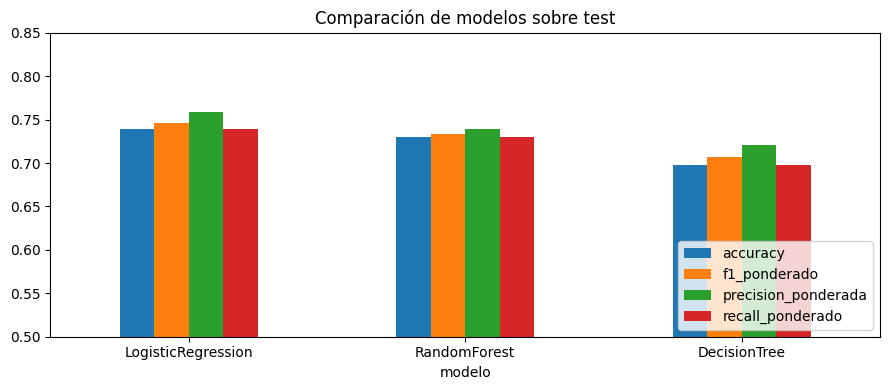

In [18]:
MEJOR = comparacion.loc[0, "modelo"]
mejor_modelo = modelos_cv[MEJOR].bestModel          # PipelineModel completo (preprocesamiento + clasificador)
print("Mejor modelo según F1 ponderado en test:", MEJOR, mejores_params[MEJOR])

ax = comparacion.set_index("modelo")[["accuracy", "f1_ponderado", "precision_ponderada", "recall_ponderado"]].plot.bar(
    figsize=(9, 4), rot=0, ylim=(0.5, 0.85))
ax.set_title("Comparación de modelos sobre test"); ax.legend(loc="lower right")
plt.tight_layout(); plt.show()

### Matriz de confusión del mejor modelo
Filas = clase real, columnas = clase predicha. La diagonal son los aciertos.

,pred: Graduate,pred: Dropout,pred: Enrolled
real: Graduate,349,10,71
real: Dropout,19,174,46
real: Enrolled,50,24,102


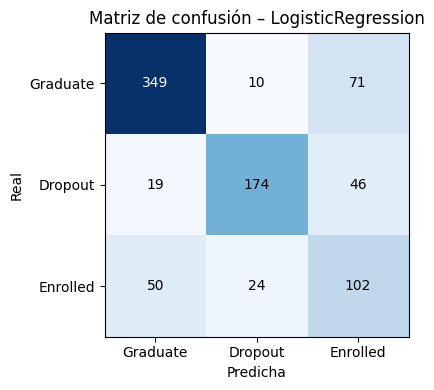

Recall por clase: {'Graduate': np.float64(0.812), 'Dropout': np.float64(0.728), 'Enrolled': np.float64(0.58)}


In [19]:
pred = predicciones[MEJOR]
cm = (pred.select(F.col("label").cast("int").alias("real"), F.col("prediction").cast("int").alias("pred"))
          .groupBy("real", "pred").count().toPandas()
          .pivot(index="real", columns="pred", values="count")
          .reindex(index=range(K), columns=range(K)).fillna(0).astype(int))
cm.index = [f"real: {c}" for c in LABELS]
cm.columns = [f"pred: {c}" for c in LABELS]
display(cm)

fig, ax = plt.subplots(figsize=(5, 4))
ax.imshow(cm.values, cmap="Blues")
ax.set_xticks(range(K), LABELS); ax.set_yticks(range(K), LABELS)
ax.set_xlabel("Predicha"); ax.set_ylabel("Real"); ax.set_title(f"Matriz de confusión – {MEJOR}")
for i in range(K):
    for j in range(K):
        v = cm.values[i, j]
        ax.text(j, i, v, ha="center", va="center", color="white" if v > cm.values.max() / 2 else "black")
plt.tight_layout(); plt.show()

recall_clase = (cm.values.diagonal() / cm.values.sum(axis=1)).round(3)
print("Recall por clase:", dict(zip(LABELS, recall_clase)))

**¿Cuál es el mejor modelo y por qué?** → **LogisticRegression** (`regParam=0.01`, `elasticNetParam=0.5`).

| Modelo | Accuracy | F1 pond. | Precisión pond. | Recall pond. | F1 Dropout | F1 Enrolled |
|---|---|---|---|---|---|---|
| **LogisticRegression** | **0,740** | **0,747** | **0,759** | **0,740** | **0,779** | **0,517** |
| RandomForest | 0,730 | 0,733 | 0,740 | 0,730 | 0,751 | 0,505 |
| DecisionTree | 0,698 | 0,707 | 0,721 | 0,698 | 0,729 | 0,454 |

1. **Gana en todas las métricas sobre test**, que es el conjunto que nunca vio. En validación cruzada el RandomForest iba apenas por delante (0,7645 frente a 0,7591), pero en test la regresión logística lo supera (0,747 frente a 0,733). Es decir, **generaliza mejor**: el bosque con `maxDepth=10` se ajustó un poco más a los datos de entrenamiento.
2. **Considerando el desbalance**, la métrica clave es el F1 ponderado, no la *accuracy*. Además, la regresión logística tiene el mejor F1 en las dos clases críticas: **`Dropout` (0,779)**, la que la universidad quiere detectar, y **`Enrolled` (0,517)**, la minoritaria. Gracias a los pesos por clase, recupera el **58 %** de los `Enrolled` (recall) y el **73 %** de los `Dropout`.
3. **Matriz de confusión:** los errores se concentran en `Enrolled`, que es un estado intermedio. 71 `Graduate` se predicen como `Enrolled` y 50 `Enrolled` como `Graduate`. Lo más importante para la universidad es que **muy pocos desertores se confunden con graduados (19)**, así que el modelo sirve como alerta temprana: rara vez dejaría pasar a un estudiante en riesgo como si fuera a graduarse.
4. **Ventajas prácticas:** es el modelo más simple y rápido de aplicar en la app. Entrega directamente **una probabilidad para cada una de las 3 clases** (softmax), que es justo lo que muestra la aplicación, y sus coeficientes se pueden interpretar.

Extraemos el `PipelineModel` completo con `bestModel` y lo guardamos a continuación.

### Guardado del mejor modelo
Guardamos el `PipelineModel` completo con `write().overwrite().save("modelo_final")`. Junto al modelo guardamos
`metadata.json`, con el orden de las clases (`labels` del `StringIndexer`), las variables que usa el modelo y
sus métricas: la app lo necesita para armar el formulario y traducir la predicción. Al final comprimimos la
carpeta en `modelo_final.zip` para descargarla y subirla al repositorio de GitHub.

In [20]:
RUTA_MODELO = "modelo_final"
mejor_modelo.write().overwrite().save(RUTA_MODELO)

metadata = {
    "modelo": MEJOR,
    "hiperparametros": mejores_params[MEJOR],
    "labels": LABELS,
    "categoricas": CAT_FINAL,
    "numericas": NUM_FINAL,
    "derivadas": DERIVADAS,
    "metricas_test": {k: float(v) for k, v in comparacion.loc[0].items() if k != "modelo"},
}
with open(os.path.join(RUTA_MODELO, "metadata.json"), "w", encoding="utf-8") as f:
    json.dump(metadata, f, indent=2, ensure_ascii=False)

shutil.make_archive("modelo_final", "zip", root_dir=".", base_dir=RUTA_MODELO)
print("Modelo guardado en", RUTA_MODELO, "y comprimido en modelo_final.zip")
print(json.dumps(metadata, indent=2, ensure_ascii=False))

Modelo guardado en modelo_final y comprimido en modelo_final.zip
{
  "modelo": "LogisticRegression",
  "hiperparametros": {
    "regParam": 0.01,
    "elasticNetParam": 0.5
  },
  "labels": [
    "Graduate",
    "Dropout",
    "Enrolled"
  ],
  "categoricas": [
    "marital_status",
    "application_mode",
    "course",
    "previous_qualification",
    "mother_s_qualification",
    "father_s_qualification",
    "mother_s_occupation",
    "father_s_occupation"
  ],
  "numericas": [
    "debtor",
    "tuition_fees_up_to_date",
    "gender",
    "scholarship_holder",
    "age_at_enrollment",
    "curricular_units_1st_sem_enrolled",
    "curricular_units_1st_sem_evaluations",
    "curricular_units_1st_sem_approved",
    "curricular_units_1st_sem_grade",
    "curricular_units_2nd_sem_enrolled",
    "curricular_units_2nd_sem_evaluations",
    "curricular_units_2nd_sem_approved",
    "curricular_units_2nd_sem_grade",
    "unemployment_rate",
    "inflation_rate",
    "gdp",
    "tasa_aprobac

Comprobamos que el modelo guardado se puede volver a cargar con `PipelineModel.load` (igual que en la app) y que
predice sobre filas que no traen `target` ni `label`, como llegarán desde el formulario.

In [21]:
recargado = PipelineModel.load(RUTA_MODELO)
muestra = test.drop("target", "label", "class_weight").limit(5)
(recargado.transform(muestra)
    .withColumn("clase_predicha", F.element_at(F.array(*[F.lit(l) for l in LABELS]), F.col("prediction").cast("int") + 1))
    .select("clase_predicha", "probability").show(truncate=False))

+--------------+-------------------------------------------------------------+
|clase_predicha|probability                                                  |
+--------------+-------------------------------------------------------------+
|Dropout       |[0.212652145983197,0.44268964446740355,0.34465820954939935]  |
|Dropout       |[0.018274634129185213,0.8560829316779804,0.12564243419283416]|
|Graduate      |[0.9158810633889254,0.005613217580555748,0.07850571903051885]|
|Enrolled      |[0.23140193717322696,0.38021947193555167,0.3883785908912214] |
|Enrolled      |[0.1975945698732484,0.395720587205484,0.4066848429212676]    |
+--------------+-------------------------------------------------------------+



Descarga del zip (solo en Google Colab):

In [22]:
try:
    from google.colab import files
    files.download("modelo_final.zip")
except ImportError:
    print("No estamos en Colab: el zip quedó en", os.path.abspath("modelo_final.zip"))

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

---
## Conclusiones

- Construimos con Spark ML un clasificador multiclase (`Dropout`, `Enrolled`, `Graduate`) para alerta temprana de deserción. El mejor modelo es una **regresión logística multinomial** con regularización elastic net, con **F1 ponderado de 0,747** y **accuracy de 0,740** sobre test.
- El **rendimiento académico de los dos primeros semestres** es lo que más predice el resultado, sobre todo las tasas de aprobación que creamos como variables derivadas. Le siguen factores económicos: tener la matrícula al día, ser becario y no tener deudas.
- El **desbalance** se trató con pesos por clase y F1 ponderado como métrica de selección. La clase minoritaria `Enrolled` sigue siendo la más difícil (F1 ≈ 0,52) porque es un estado intermedio entre las otras dos. Un siguiente paso sería agregar información de semestres posteriores o probar modelos de *boosting* (`GBTClassifier` con estrategia uno contra todos).
- El `PipelineModel` guardado (`modelo_final`) incluye todo el preprocesamiento. La app de Streamlit solo tiene que calcular las 4 variables derivadas, crear un DataFrame de Spark con los datos del formulario y aplicar `transform`, usando el orden de clases `LABELS` guardado en `metadata.json`.